POE: Pipelines and Text Data

Name: Pfunzo Madzhiga

Student no.: ST10543942

In [2]:
# Import libraries for data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option('display.max_columns', None)

# Display plots within the notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the medical drug reviews dataset
data = pd.read_csv("positive_negative_balanced.csv")

# Display the first five records
data.head()

,id,drugName,condition,review,rating,date,usefulCount
0,84365,Ethinyl estradiol / norgestimate,Birth Control,I just started my 3rd cycle of the sprintec pi...,1,2016-12-25,2
1,158251,Ziprasidone,Bipolar Disorde,I've taken Geodon for the past year and it's t...,1,2011-08-03,26
2,217050,Oxcarbazepine,Bipolar Disorde,I have taken trileptal for many years....I cou...,1,2014-07-16,29
3,70564,Flomax,Benign Prostatic Hyperplasia,After a few days Flomax did work and increased...,0,2015-12-13,47
4,67856,Plan B,Emergency Contraception,"I had unprotected sex on August 10, also the l...",1,2016-09-03,10


In [4]:
# Check the number of rows and columns
print("Dataset dimensions:", data.shape)

# Display the column names
print("\nDataset columns:")
print(data.columns.tolist())

Dataset dimensions: (107144, 7)

Dataset columns:
['id', 'drugName', 'condition', 'review', 'rating', 'date', 'usefulCount']


In [5]:
# Examine the structure and data types
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 107144 entries, 0 to 107143
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   id           107144 non-null  int64
 1   drugName     107144 non-null  str  
 2   condition    106531 non-null  str  
 3   review       107144 non-null  str  
 4   rating       107144 non-null  int64
 5   date         107144 non-null  str  
 6   usefulCount  107144 non-null  int64
dtypes: int64(3), str(4)
memory usage: 54.6 MB


In [6]:
# Check missing values in each column
data.isnull().sum()

id               0
drugName         0
condition      613
review           0
rating           0
date             0
usefulCount      0
dtype: int64

In [7]:
# Count duplicate records
print("Number of duplicate records:", data.duplicated().sum())

Number of duplicate records: 0


rating
1    53572
0    53572
Name: count, dtype: int64


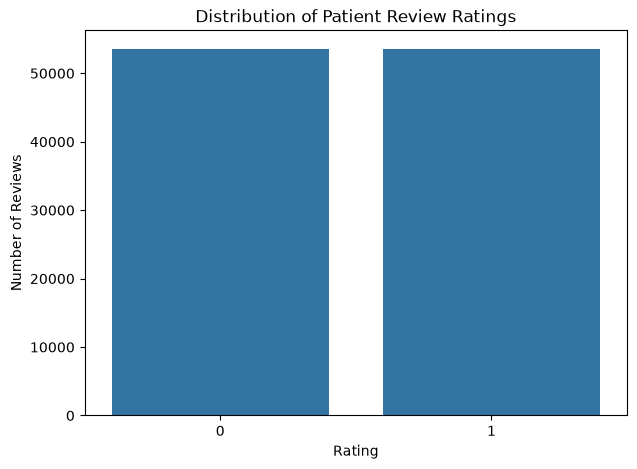

In [8]:
# Count the observations for each rating
print(data["rating"].value_counts())

# Visualise the rating distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=data, x="rating")

plt.title("Distribution of Patient Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

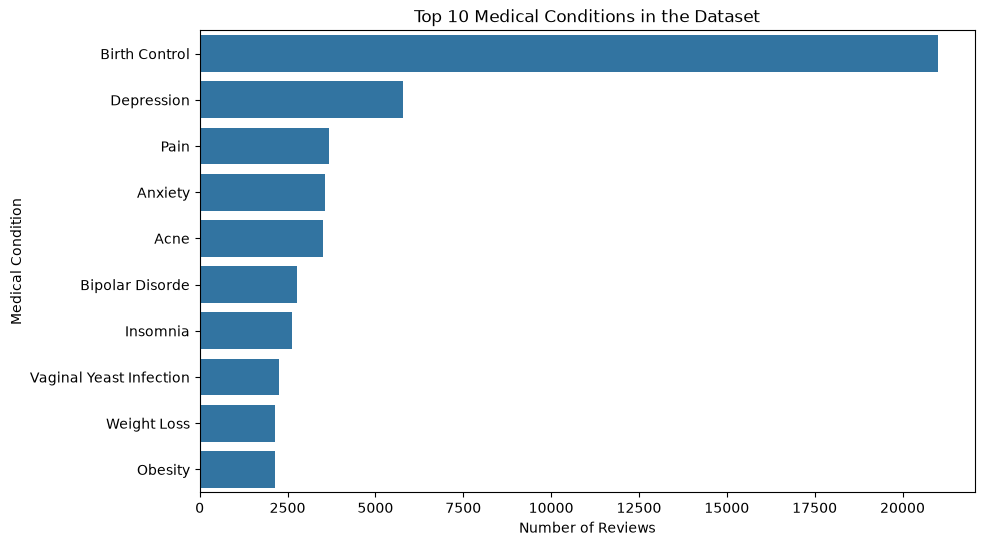

In [9]:
# Identify the 10 most frequently reviewed conditions
top_conditions = data["condition"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_conditions.values, y=top_conditions.index)

plt.title("Top 10 Medical Conditions in the Dataset")
plt.xlabel("Number of Reviews")
plt.ylabel("Medical Condition")
plt.show()

count    107144.000000
mean         83.385108
std          45.252974
min           1.000000
25%          47.000000
50%          82.000000
75%         125.000000
max        1894.000000
Name: review_length, dtype: float64


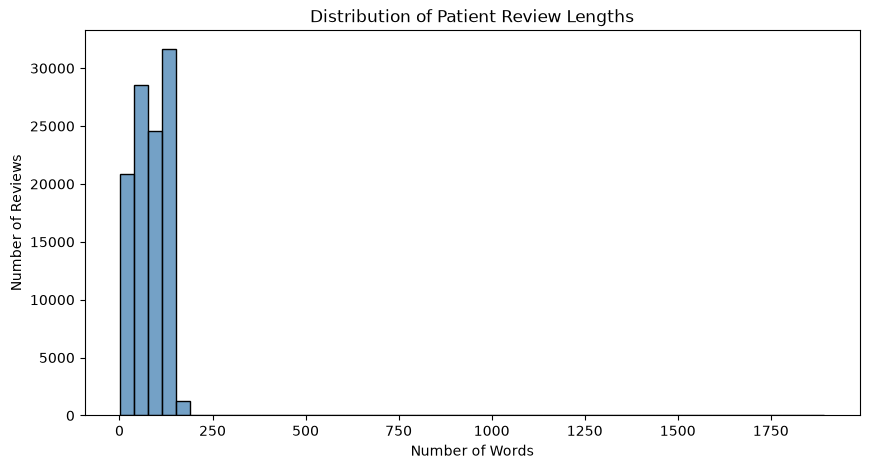

In [10]:
# Calculate the number of words in each review
data["review_length"] = data["review"].apply(
    lambda x: len(str(x).split())
)

# Display summary statistics
print(data["review_length"].describe())

# Visualise the distribution of review lengths
plt.figure(figsize=(10, 5))

sns.histplot(
    data["review_length"],
    bins=50,
    color="steelblue"
)

plt.title("Distribution of Patient Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()

In [11]:
import re
import html

# Function to clean patient reviews
def clean_text(text):
    text = html.unescape(str(text))
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove special characters but keep words and numbers
    text = re.sub(r"[^a-z0-9\s']", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Apply text cleaning
data["clean_review"] = data["review"].apply(clean_text)

# Compare original and cleaned reviews
print("Original Review:")
print(data["review"].iloc[0])

print("\nCleaned Review:")
print(data["clean_review"].iloc[0])

Original Review:
I just started my 3rd cycle of the sprintec pills. This is my experience. 

1st month: nausea, emotional, sensitive breasts, and terrible acne.  
2nd: acne flare-up at the beginning of the month and similar symptoms to first month.
3rd:another acne flare-up, this time the break-out is worser than month 2.

 For me the biggest problem is the acne. I have struggled with acne my whole life, so it's nothing new to deal with. However, the worse experience I had with acne was when I was 13-15 years old; on sprintec, my skin has reversed itself to my teenage years -- maybe even a little worse.  I talked with my dermatologist and physician and both told me to stay optimistic about the future of my skin - saying clearer skin comes around month 4.

Cleaned Review:
i just started my 3rd cycle of the sprintec pills this is my experience 1st month nausea emotional sensitive breasts and terrible acne 2nd acne flare up at the beginning of the month and similar symptoms to first month

        Word  Frequency
232      day      37243
869   taking      33739
937       ve      30925
656     pain      30276
603   months      28987
531     like      28507
824  started      28054
302  effects      27946
992    years      27524
233     days      26891
498     just      26217
894     time      25513
343     feel      22619
674     pill      21637
904     took      19989


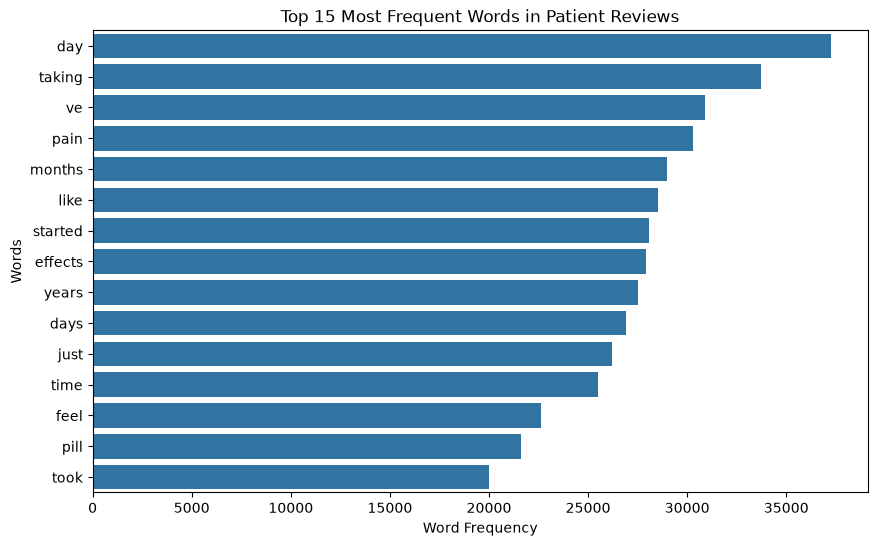

In [12]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a CountVectorizer
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=1000
)

# Convert cleaned reviews into word counts
word_matrix = vectorizer.fit_transform(
    data["clean_review"]
)

# Calculate total word frequencies
word_counts = word_matrix.sum(axis=0).A1

# Create a DataFrame
word_freq = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "Frequency": word_counts
})

# Select the 15 most frequent words
top_words = word_freq.sort_values(
    by="Frequency",
    ascending=False
).head(15)

print(top_words)

# Plot the results
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_words,
    x="Frequency",
    y="Word"
)

plt.title("Top 15 Most Frequent Words in Patient Reviews")
plt.xlabel("Word Frequency")
plt.ylabel("Words")

plt.show()

In [15]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Additional stopwords for topic modelling
extra_stopwords = [
    "ve", "ll", "re", "don", "didn",
    "just", "like", "really", "got"
]

# Combine English stopwords with additional words
from sklearn.feature_extraction import text

stop_words = list(
    text.ENGLISH_STOP_WORDS.union(extra_stopwords)
)

# Convert reviews into a document-term matrix
lda_vectorizer = CountVectorizer(
    stop_words=stop_words,
    max_df=0.95,
    min_df=10,
    max_features=3000
)

lda_matrix = lda_vectorizer.fit_transform(
    data["clean_review"]
)

# Train the LDA model
lda_model = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    learning_method="online",
    max_iter=10
)

lda_model.fit(lda_matrix)

print("LDA model trained successfully!")

LDA model trained successfully!


In [16]:
# Display the top 10 words for each topic
feature_names = lda_vectorizer.get_feature_names_out()

for topic_index, topic in enumerate(lda_model.components_):
    top_words = [
        feature_names[i]
        for i in topic.argsort()[-10:][::-1]
    ]

    print(f"Topic {topic_index + 1}:")
    print(", ".join(top_words))
    print()

Topic 1:
years, works, life, work, effects, tried, drug, medicine, great, day

Topic 2:
pain, skin, days, day, severe, using, doctor, weeks, started, face

Topic 3:
day, took, night, hours, taking, sleep, days, felt, feel, morning

Topic 4:
anxiety, taking, started, feel, depression, effects, weight, months, weeks, medication

Topic 5:
period, pill, months, control, birth, month, bleeding, sex, periods, weight



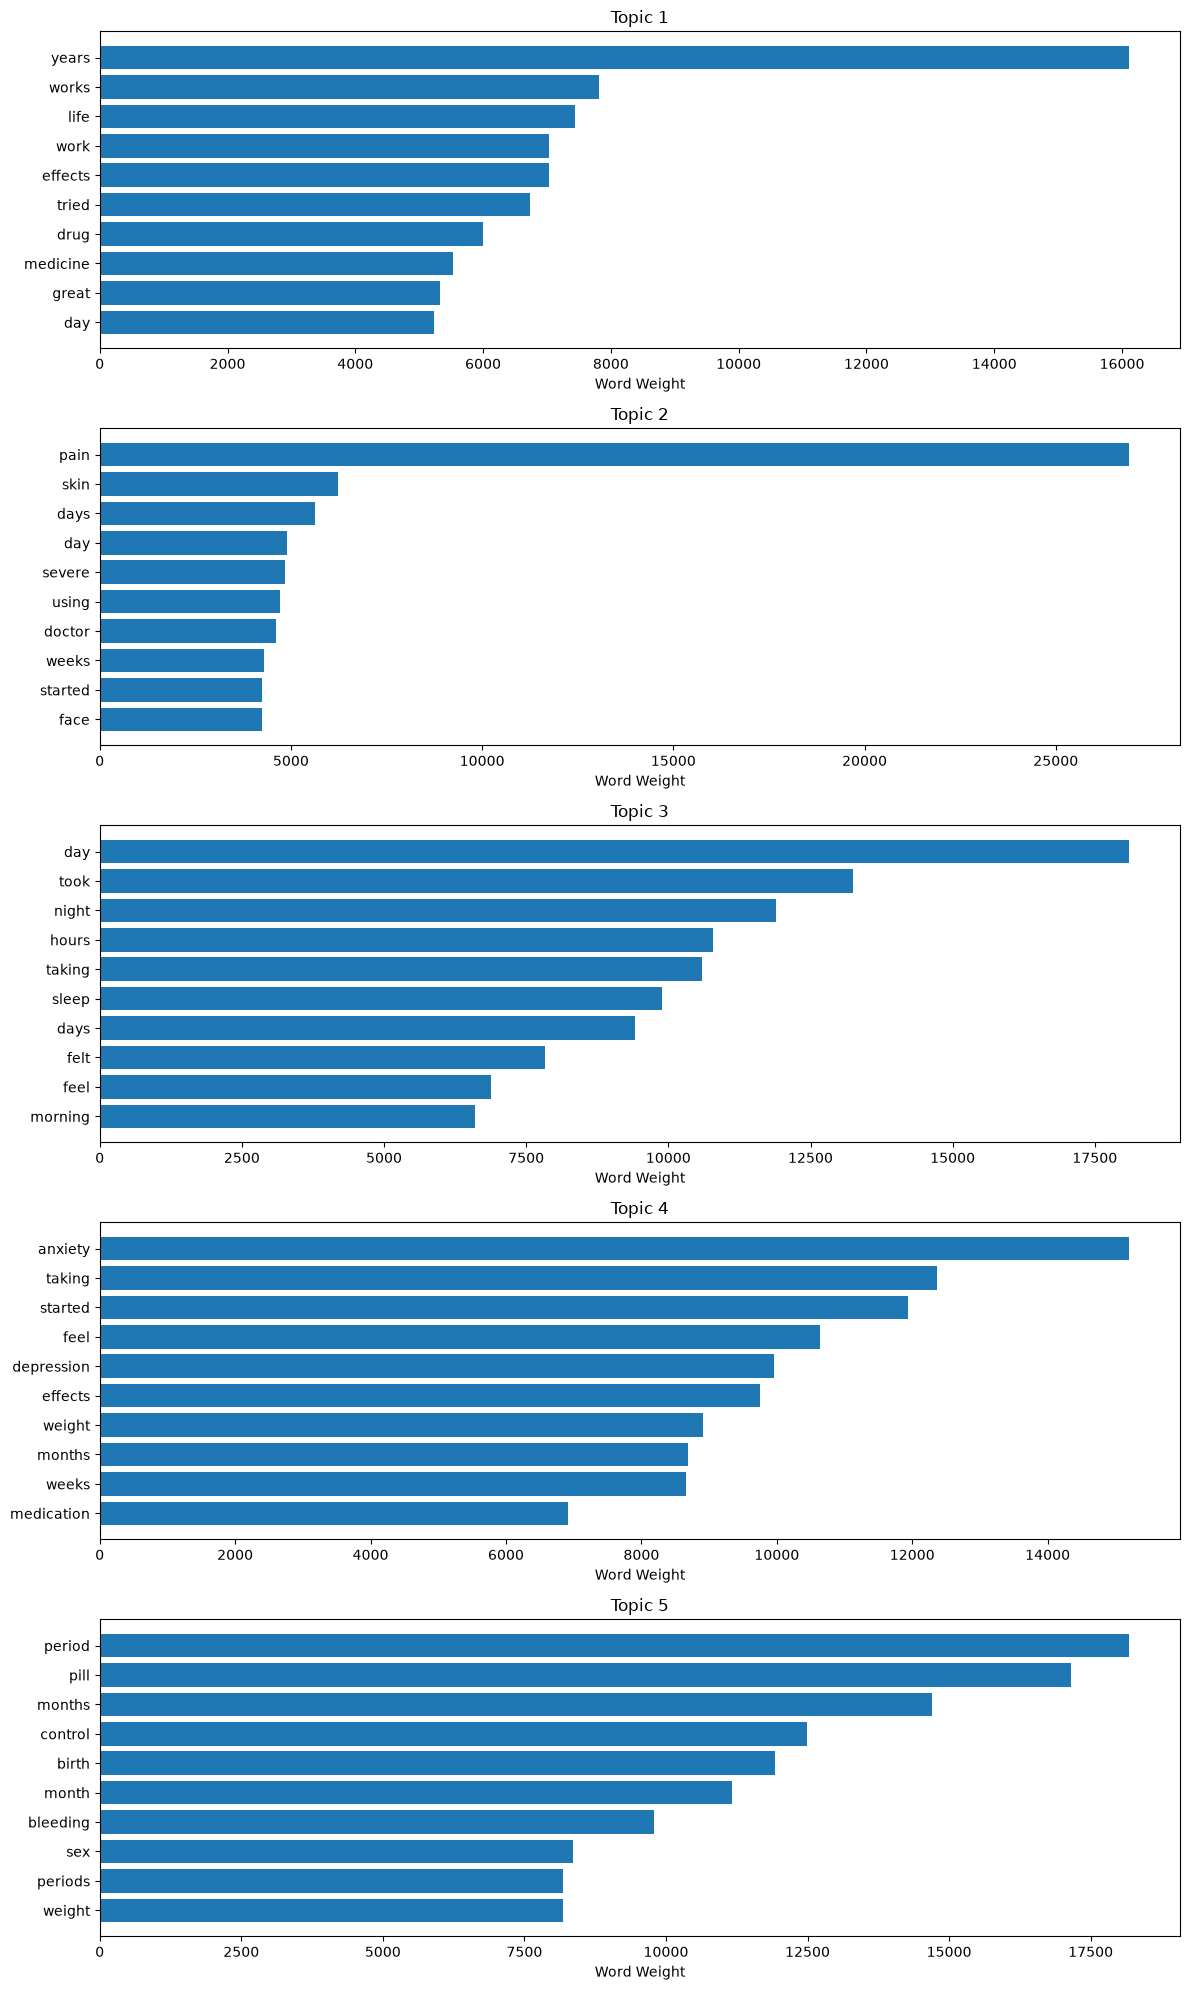

In [17]:
import matplotlib.pyplot as plt
import numpy as np

feature_names = lda_vectorizer.get_feature_names_out()

fig, axes = plt.subplots(5, 1, figsize=(12, 20))

for topic_idx, topic in enumerate(lda_model.components_):

    top_indices = topic.argsort()[-10:][::-1]

    words = [feature_names[i] for i in top_indices]
    weights = topic[top_indices]

    axes[topic_idx].barh(words[::-1], weights[::-1])

    axes[topic_idx].set_title(f"Topic {topic_idx + 1}")
    axes[topic_idx].set_xlabel("Word Weight")

plt.tight_layout()
plt.show()

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Define features and target
X = data["clean_review"]
y = data["rating"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create TF-IDF and Logistic Regression pipeline
sentiment_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=3
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
sentiment_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Logistic Regression model trained successfully!
Training samples: 85715
Testing samples: 21429


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict ratings for the test dataset
y_pred = sentiment_model.predict(X_test)

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Display results
print("MODEL EVALUATION RESULTS")
print("-------------------------")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

MODEL EVALUATION RESULTS
-------------------------
Accuracy:  0.8806
Precision: 0.8820
Recall:    0.8788
F1-score:  0.8804

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.88      0.88     10715
           1       0.88      0.88      0.88     10714

    accuracy                           0.88     21429
   macro avg       0.88      0.88      0.88     21429
weighted avg       0.88      0.88      0.88     21429



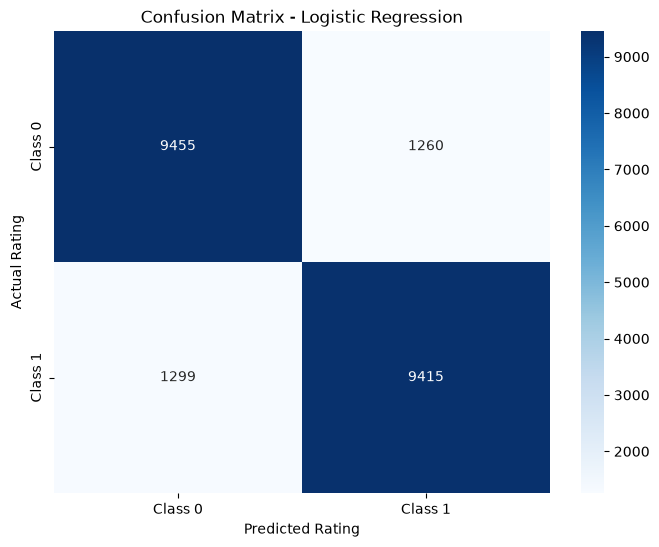

Confusion Matrix:
[[9455 1260]
 [1299 9415]]


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")

plt.show()

# Display numerical values
print("Confusion Matrix:")
print(cm)

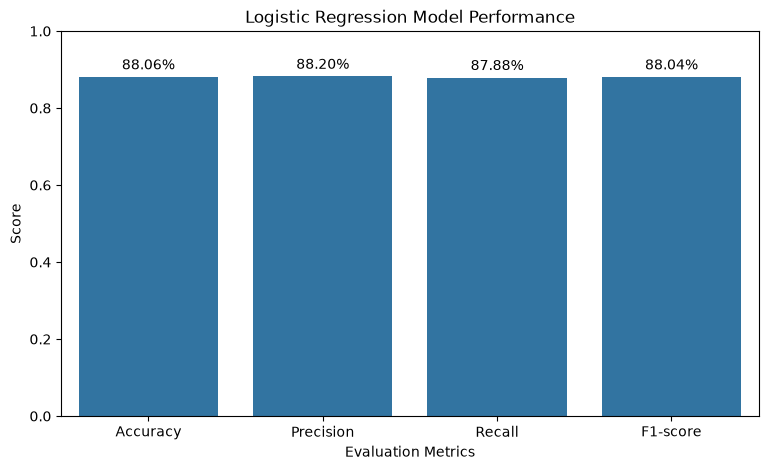

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
scores = [accuracy, precision, recall, f1]

plt.figure(figsize=(9, 5))

sns.barplot(x=metrics, y=scores)

plt.title("Logistic Regression Model Performance")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)

for i, score in enumerate(scores):
    plt.text(i, score + 0.02, f"{score:.2%}",
             ha="center")

plt.show()